In [1]:
import numpy as np
import os
from matplotlib import pyplot as plt
import glob

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 300

dirDir = "/home/users/l/lebrun/"
dataPath = dirDir + "data/"
figPath = dirDir + "figures/"
resultPath = dirDir + "results/exposureMaps/10GeV/"
print(resultPath)

/home/users/l/lebrun/results/exposureMaps/10GeV/


In [ ]:
datas = list()
# Use glob to parse all .npz files in the directory
for file in glob.glob(os.path.join(resultPath, "*.npz")):
    data = np.load(file)
    datas.append(data)

lon_edges = datas[0]["lon_edges"]
lat_edges = datas[0]["lat_edges"]
lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])
datas = np.array([data["exposure_map"] for data in datas])
print(f"Files found: {len(datas)}")

print("Shape of data:", datas.shape)
print("Shape of data element:", datas[0].shape)


[NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2023-04-10.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2023-12-28.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2023-03-12.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2020-10-22.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2018-12-15.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2022-08-15.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2017-03-23.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/exposureMaps/10GeV/2017-11-18.npz' with keys: lon_edges, lat_edges, exposure_map, NpzFile '/home/users/l/lebrun/results/e

In [ ]:
# SUm all the exposure maps

exposureMap = np.sum(datas, axis=0)
    

In [1]:

from matplotlib.colors import LogNorm
def plot_exposure_map(lon_centers, lat_centers, exposure_map):
    """ Plot the exposure map in Mollweide projection.  
    Args:
        lon_centers (np.ndarray): 1D array of galactic longitudes in radians.
        lat_centers (np.ndarray): 1D array of galactic latitudes in radians.
        exposure_map (np.ndarray): 2D array of exposure values.
        figPath (str, optional): Path to save the figure. If None, the figure is shown.
    """

    # Convert your 1D radian lon/lat centers into 2D grid
    lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers, indexing='ij')

    # Convert to Mollweide's expected range: [-π, π] in lon, [-π/2, π/2] in lat
    lon_plot = lon_grid.T  # Transpose to match shape
    lat_plot = lat_grid.T
    exposure_plot = exposure_map.T  # Transpose as well to match pcolormesh layout

    # Plot
    fig = plt.figure(figsize=(10, 5))
    ax = fig.add_subplot(111, projection='mollweide')

    # Plot with pcolormesh (lon, lat must be in radians)
    mesh = ax.pcolormesh(lon_plot, lat_plot, exposure_plot, cmap='viridis', shading='auto', norm=LogNorm())

    # Final touches
    fig.colorbar(mesh, ax=ax, label='Exposure [cm² s]')
    ax.set_title('Exposure Map in Galactic Coordinates (Mollweide Projection)')
    tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel('Galactic Longitude')
    ax.set_ylabel('Galactic Latitude')
    ax.grid(True)

    return fig

In [2]:
# Plotting the results
fig = plot_exposure_map(lon_centers, lat_centers,exposureMap)
plt.show()

NameError: name 'lon_centers' is not defined

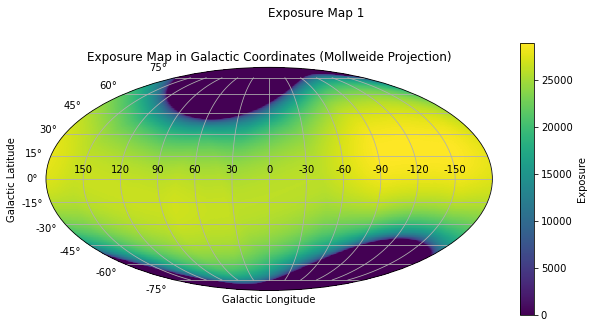

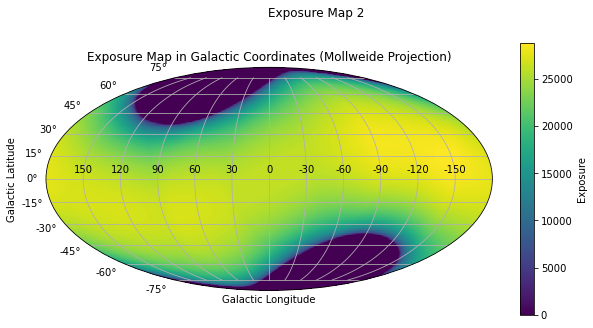

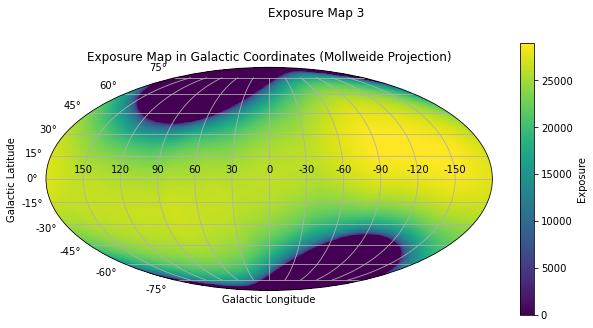

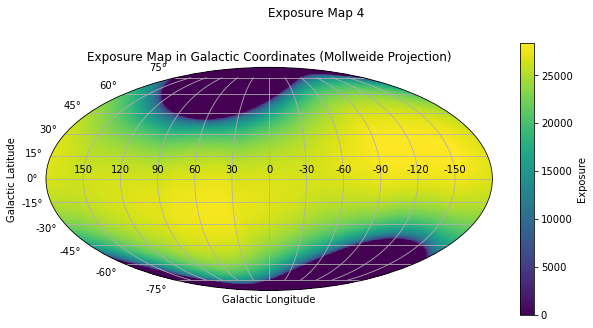

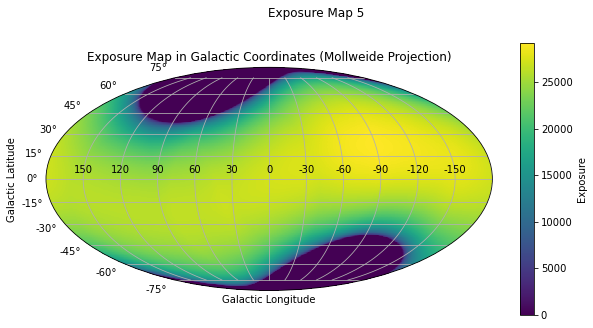

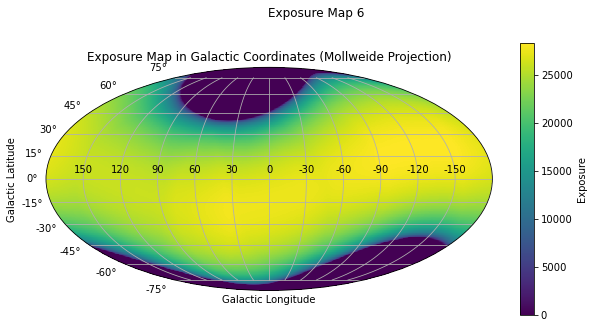

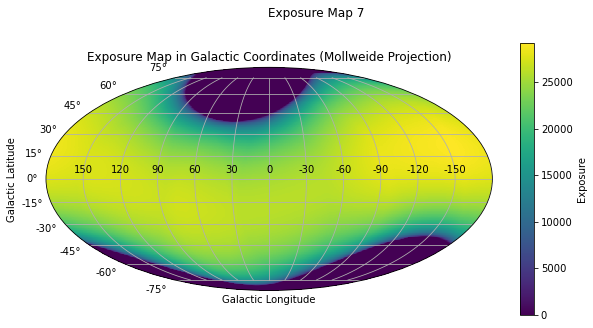

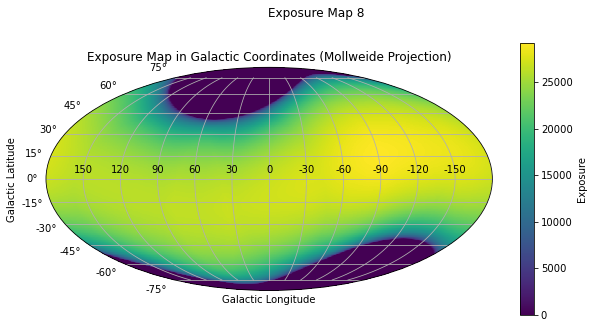

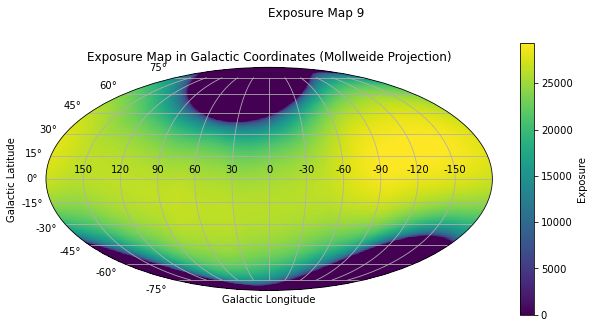

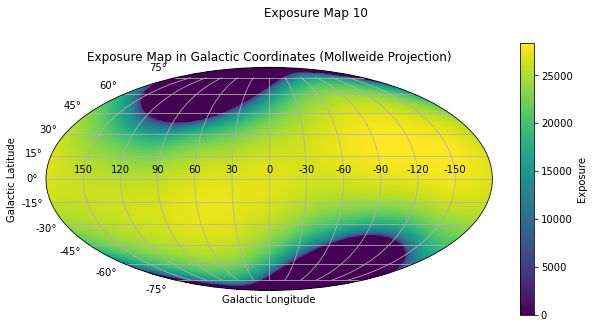

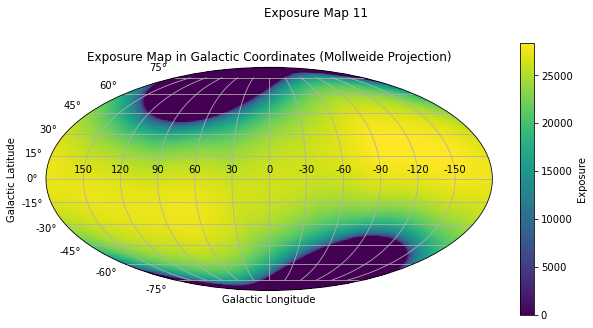

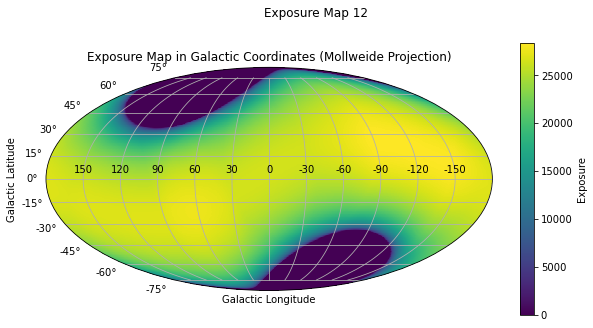

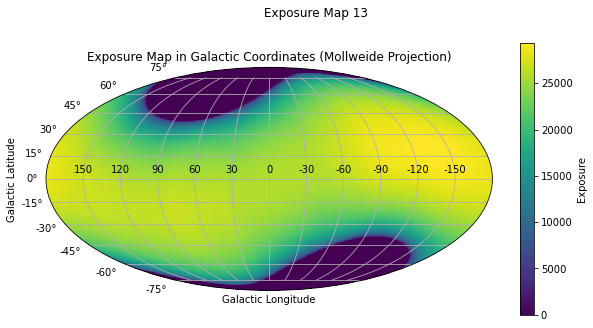

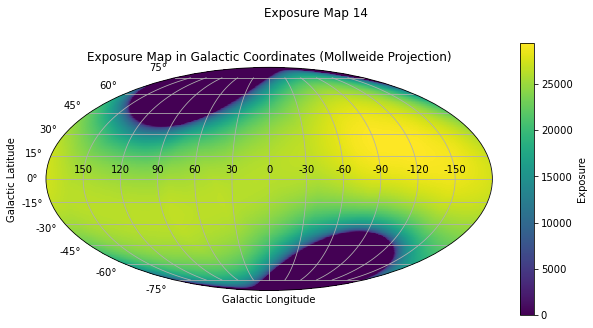

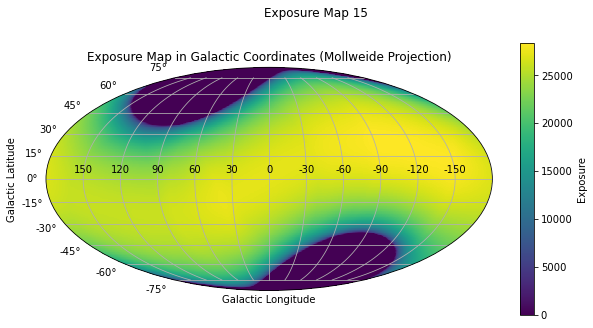

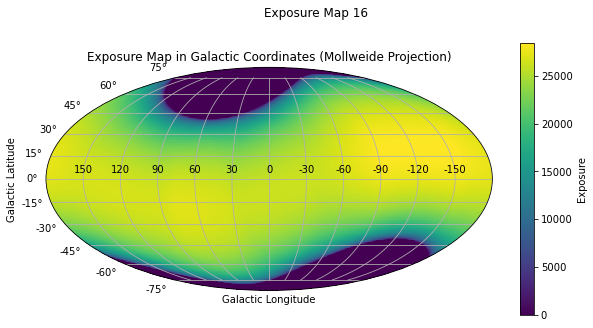

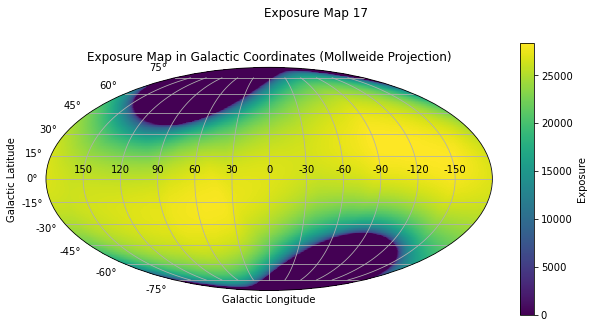

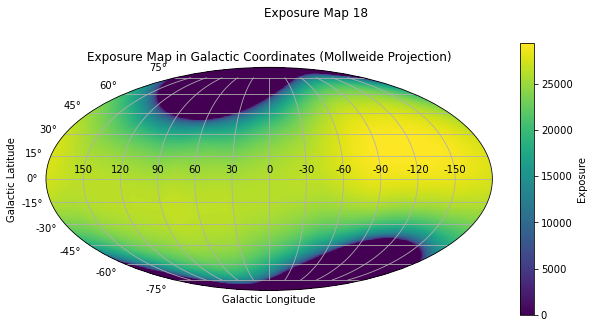

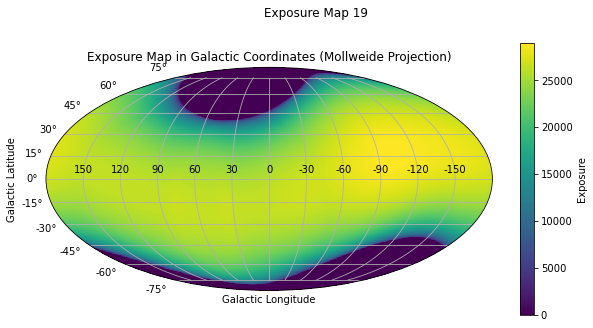

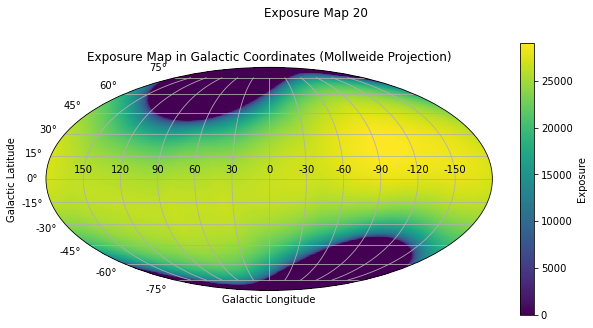

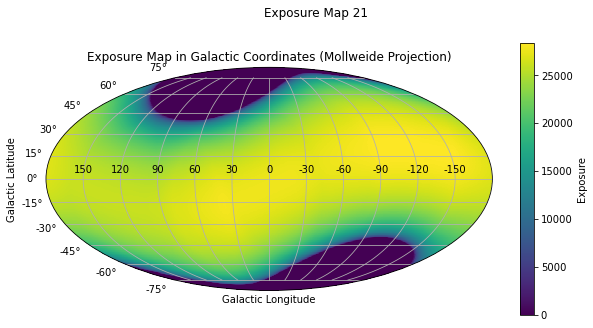

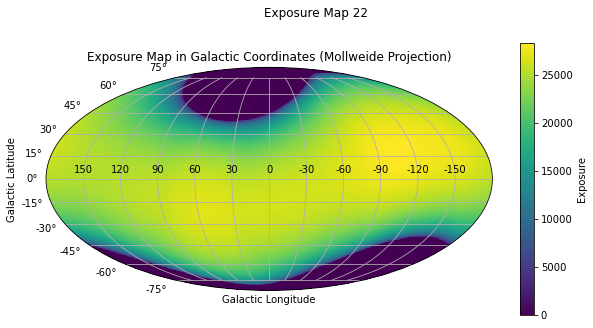

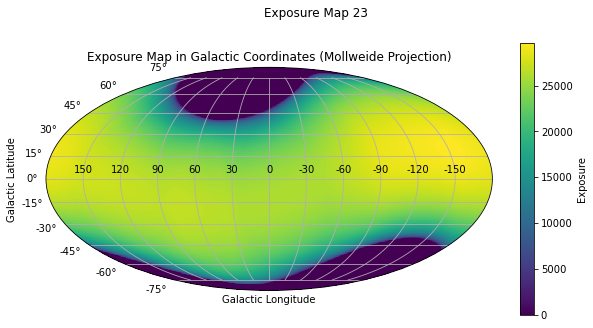

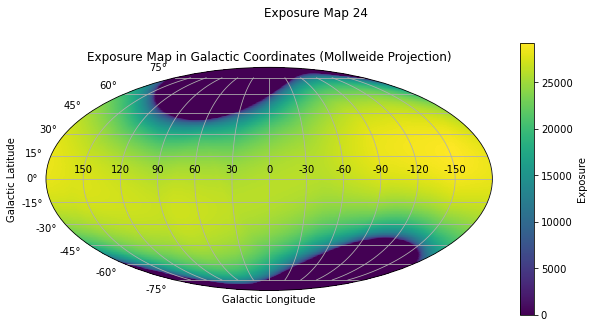

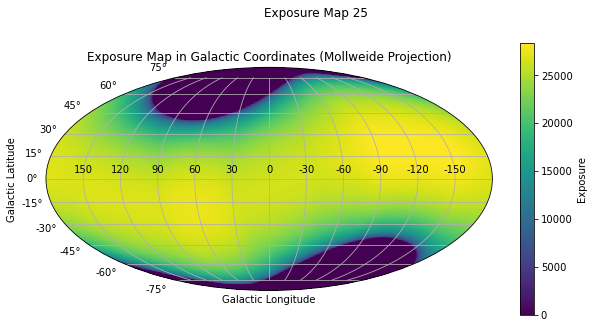

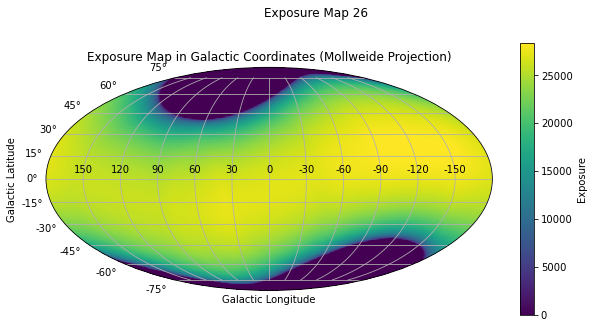

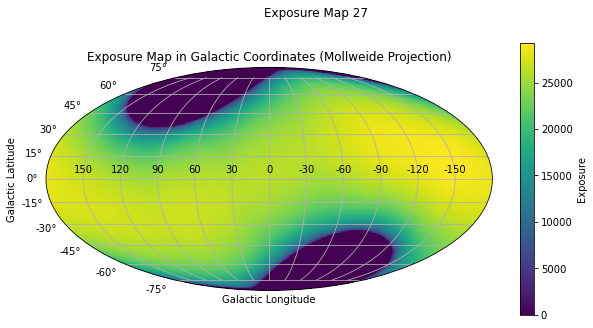

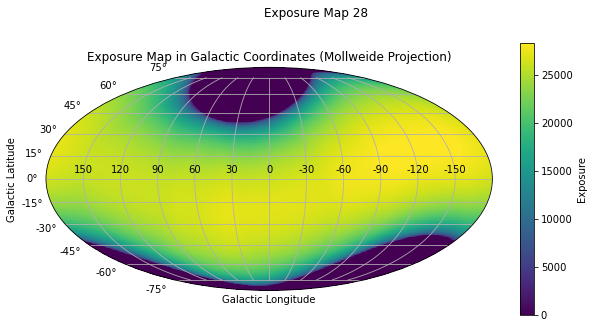

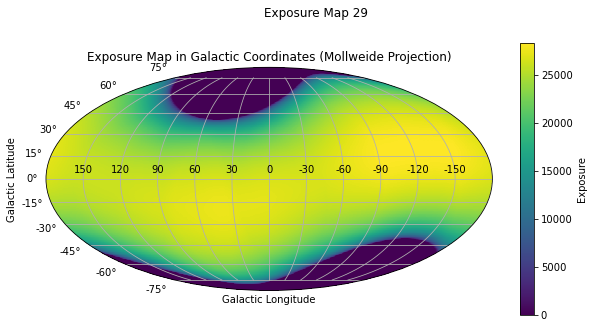

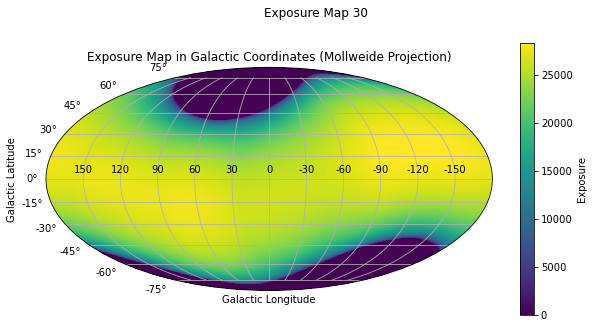

In [ ]:
# Plot all data 
for i, data in enumerate(datas):
    fig = plot_exposure_map(lon_centers, lat_centers, data)
    fig.suptitle(f"Exposure Map {i+1}")
    plt.show()